# 03 — Demand ranking by role

**Step 12 (M3).** Which skills does each role family actually ask for? We cut the
skill hits by role and rank *within* each role, then show the whole picture as a
skill × role heatmap.

Role buckets: `data analyst`, `data scientist`, `analytics engineer`, and a merged
**`bi`** family (the two BI queries are too small to rank alone). Metric is
**share of a role's distinct jobs** that mention a skill — the same share unit as
notebook 01, but computed with a per-role denominator so roles of very different
sizes stay comparable.

In [1]:
import sqlite3
import sys
from pathlib import Path

import pandas as pd

# The notebook lives in notebooks/; put the repo root on sys.path so
# `import jobskills` resolves no matter where Jupyter was launched from.
REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from jobskills import config

# Pull only the columns this analysis needs. `ident` is the step-10 cross-source
# job identity (dedup_key, or an id-based fallback) — collapsing on it is how we
# count *distinct jobs* rather than raw rows. We compute it in SQL so the notebook
# never re-derives the dedup logic.
with sqlite3.connect(config.SQLITE_PATH) as conn:
    jobs = pd.read_sql_query(
        "SELECT id, role_query, COALESCE(dedup_key, 'id:' || id) AS ident FROM jobs",
        conn,
    )
    hits = pd.read_sql_query("SELECT posting_id, skill FROM skill_hits", conn)

len(jobs), len(hits)

(1423, 1014)

In [2]:
# Map the raw search query to a role bucket: the two BI queries fold into one
# family, everything else stays as-is.
BI_QUERIES = {"business intelligence analyst", "business intelligence developer"}
jobs["role"] = jobs["role_query"].where(~jobs["role_query"].isin(BI_QUERIES), "bi")

# Denominator source: one row per distinct (job, role). A job can be found by more
# than one role's query, so it legitimately appears under each role that surfaced
# it — but only ONCE per role (drop_duplicates kills the intra-role repeats that
# overlapping queries + the dedup collapse would otherwise leave).
jobs_r = jobs[["ident", "role"]].drop_duplicates()

# Numerator source: attach each skill hit to its job's ident + role, then make the
# (job, role, skill) triples distinct so one job counts once per role per skill.
hits_r = (
    hits.merge(jobs[["id", "ident", "role"]], left_on="posting_id", right_on="id")
    [["ident", "role", "skill"]]
    .drop_duplicates()
)

jobs_r["role"].value_counts()

role
data analyst          527
data scientist        443
analytics engineer    185
bi                     35
Name: count, dtype: int64

In [3]:
# Per-role denominator: distinct jobs in each role bucket.
role_totals = jobs_r["role"].value_counts()

# Numerator: distinct jobs per (role, skill). hits_r is already deduped to one row
# per (ident, role, skill), so a plain groupby size IS the distinct-job count.
skill_counts = hits_r.groupby(["role", "skill"]).size().rename("n_jobs").reset_index()

# Share = jobs-in-role-with-skill / jobs-in-role. Dividing by role_totals (indexed
# by role) broadcasts the right denominator onto each row via its `role` value.
skill_counts["share"] = skill_counts["n_jobs"] / skill_counts["role"].map(role_totals)

# Long → wide: skills as rows, roles as columns, share as the cell. Missing
# (role, skill) pairs mean the skill never appeared in that role → fill 0.
share_matrix = skill_counts.pivot(index="skill", columns="role", values="share").fillna(0.0)

share_matrix.shape

(52, 4)

In [4]:
# Which skills to show: the UNION of each role's top-K. A global top-N would hide
# a skill that's big in one role only (the whole point of a per-role view), so we
# take each column's K largest and union the skills that surface.
TOP_K = 8
top_skills = set()
for role in share_matrix.columns:
    top_skills |= set(share_matrix[role].nlargest(TOP_K).index)

# Keep only those rows; order them by overall demand (row max share) so the
# heatmap reads roughly strongest-skill-first down the y-axis.
heat = share_matrix.loc[list(top_skills)]
heat = heat.loc[heat.max(axis=1).sort_values(ascending=False).index]

print(f"{len(heat)} skills shown (union of each role's top {TOP_K})")
(heat * 100).round(1)

18 skills shown (union of each role's top 8)


role,analytics engineer,bi,data analyst,data scientist
skill,,,,
ai,24.3,14.3,12.1,33.4
machine learning,3.8,2.9,2.3,19.6
sql,2.7,11.4,5.3,1.4
azure,3.8,8.6,1.3,0.7
etl,0.0,8.6,1.3,0.2
sql server,0.0,5.7,0.2,0.0
tableau,0.5,5.7,0.8,0.7
power bi,2.7,2.9,5.5,0.2
snowflake,4.3,2.9,0.6,0.5


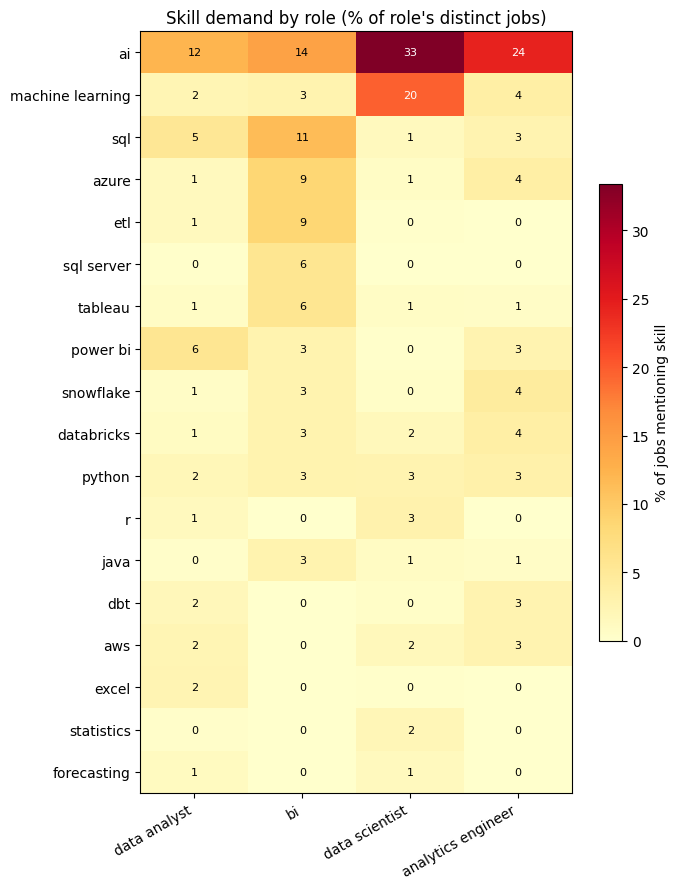

In [5]:
import matplotlib.pyplot as plt

# Order the role columns as a reader would scan them (generalist -> specialist).
ROLE_ORDER = ["data analyst", "bi", "data scientist", "analytics engineer"]
grid = heat[ROLE_ORDER] * 100  # work in percentage points

fig, ax = plt.subplots(figsize=(7, 9))
# imshow paints the matrix as coloured cells; each value maps to a colour via the
# colormap. aspect="auto" lets cells stretch to fill the figure instead of forcing
# squares. We build the heatmap by hand (no seaborn) so nothing is hidden.
im = ax.imshow(grid.values, cmap="YlOrRd", aspect="auto")

# Ticks: columns = roles, rows = skills. imshow indexes rows top-to-bottom, which
# already matches our strongest-first row order.
ax.set_xticks(range(len(grid.columns)), grid.columns, rotation=30, ha="right")
ax.set_yticks(range(len(grid.index)), grid.index)

# Annotate each cell with its share. White text on the dark (high) cells, black on
# the light ones, so the number stays readable against the fill.
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        val = grid.values[i, j]
        ax.text(j, i, f"{val:.0f}", ha="center", va="center",
                color="white" if val > grid.values.max() / 2 else "black", fontsize=8)

ax.set_title("Skill demand by role (% of role's distinct jobs)")
fig.colorbar(im, ax=ax, label="% of jobs mentioning skill", shrink=0.6)
fig.tight_layout()
plt.show()

## Reading this honestly — three caveats

- **`role` is the *search query*, not the posting's true role.** A job lands in a
  bucket because that query surfaced it, not because a human classified it. Adzuna's
  full-text search is loose, so a bucket carries some off-target postings.
- **Remotive collapses into `data analyst`.** All 34 remote jobs sit under that one
  bucket — the step-10 dedup kept the first-seen query when the same remote job
  matched several role searches. So the `data analyst` column is the only one mixing
  in remote/full-description jobs, which nudges its shares up relative to the
  Adzuna-only buckets.
- **`bi` is small-n (35 jobs).** One posting moves its share by ~3 percentage points,
  so treat the BI column as indicative, not precise.

Underlying all of it: Adzuna descriptions are truncated at 500 chars (the step-11b
finding), so absolute shares are a floor, not the true demand rate. The *relative*
pattern across roles is the signal here, not the absolute numbers.